In [1]:
import pandas as pd
import numpy as np
import glob
import os

ROOT = "Returns Data"

folders = [
    "Forex_Data",
    "Commodity_Data",
    "Crypto_Data",
    "Bond_returns",
    "stock_returns"
]

for folder in folders:
    path = os.path.join(ROOT, folder)
    files = glob.glob(os.path.join(path, "*.csv"))
    print(folder, len(files))




Forex_Data 16
Commodity_Data 15
Crypto_Data 15
Bond_returns 20
stock_returns 20


In [2]:
returns = {}
for folder in folders:
    path = os.path.join(ROOT, folder)
    files = glob.glob(os.path.join(path, "*.csv"))
    for file in files:
        asset= os.path.splitext(os.path.basename(file))[0]
        df = pd.read_csv(file)
        df["Date"] = pd.to_datetime(df["Date"], errors= "coerce")
        df= df.dropna(subset=["Date","Return"])
        df =df.sort_values("Date")
        returns[asset]= df.set_index("Date")["Return"]
print("Assets loaded:", len(returns))


Assets loaded: 86


In [3]:
R = pd.concat(returns, axis=1)
R = R[R.index.dayofweek <5]
R = R.dropna(thresh=47)
print(R.shape)



(1560, 86)


In [4]:
#construct PMFG
import networkx as nx
import matplotlib.pyplot as plt
for t in    range(0,len(R)-260-4):
    window= R.iloc[t:t+260]
    test= R.iloc[t+260:t+265]

def PMFG_graph(window):
    corr_matrix= window.corr(method="pearson")
    corr= corr_matrix.copy()

    #remove self correlations and select correlations for edges
    np.fill_diagonal(corr.values, np.nan)
    edges= []
    for i in corr.columns:
        for j in corr.columns:
            if i<j:
                edges.append((i,j,corr.loc[i,j]))

    #sort from strongest to weakest correlation
    edges= sorted(edges, key= lambda x: x[2], reverse=True)

    PMFG= nx.Graph()
    PMFG.add_nodes_from(corr.columns)

    max_edges= 3*(len(corr.columns)-2)

    for u,v,w in edges:
        PMFG.add_edge(u,v,weight=w)
        planar, _ = nx.check_planarity(PMFG)
        if not planar:
            PMFG.remove_edge(u,v)
        if PMFG.number_of_edges()==max_edges:
            break
    return  PMFG       

In [5]:
import numpy as np
from scipy.optimize import minimize
def mean_var_strategy(train):
    mu = train.mean().values
    sigma = train.cov().values

    n = len(mu)
    w0 = np.ones(n) / n

    def objective(w):
        portfolio_return = w @ mu
        portfolio_variance = w @ sigma @ w
        return -(portfolio_return - portfolio_variance)

    constraints = [
        {"type": "eq", "fun": lambda w: np.sum(w) - 1}
    ]

    bounds = [(0, 1)] * n

    result = minimize(
        objective,
        w0,
        method="SLSQP",
        bounds=bounds,
        constraints=constraints,
        options={"ftol": 1e-8, "maxiter": 200}
    )

    return result.x



In [18]:
centralities= ["EC","DC","PR"]
portfolio_sizes= [10,20,30]

results= { c:{N: [] for N in portfolio_sizes} for c in centralities}
total= len(R)-264
for t in range(0,len(R)-260-4):
    window= R.iloc[t:t+260]
    test= R.iloc[t+260:t+265]
    
    if t%25==0 or t== total-1:
        print(f"{100*t/total:5.1f}% completed ({t}/{total})")
           
    PMFG = PMFG_graph(window)
    for c in centralities:
        if c=="EC":
                    centrality = nx.eigenvector_centrality(PMFG, weight=None, max_iter=1000, tol=1e-06) 
        elif c=="DC":
                    centrality = nx.degree_centrality(PMFG) 
        elif c=="PR":
                    centrality = nx.pagerank(PMFG, weight=None) 
    
        ranked_assets= sorted(centrality, key=centrality.get)
        for N in portfolio_sizes:
            selected= ranked_assets[:N]
            train= window[selected]
            weights= mean_var_strategy(train)
            daily_portfolio_returns = test[selected]@weights
            Rnet= np.sum(daily_portfolio_returns)
            results[c][N].append(Rnet)

np.save("results.npy",results)
      



  0.0% completed (0/1296)
  1.9% completed (25/1296)
  3.9% completed (50/1296)
  5.8% completed (75/1296)
  7.7% completed (100/1296)
  9.6% completed (125/1296)
 11.6% completed (150/1296)
 13.5% completed (175/1296)
 15.4% completed (200/1296)
 17.4% completed (225/1296)
 19.3% completed (250/1296)
 21.2% completed (275/1296)
 23.1% completed (300/1296)
 25.1% completed (325/1296)
 27.0% completed (350/1296)
 28.9% completed (375/1296)
 30.9% completed (400/1296)
 32.8% completed (425/1296)
 34.7% completed (450/1296)
 36.7% completed (475/1296)
 38.6% completed (500/1296)
 40.5% completed (525/1296)
 42.4% completed (550/1296)
 44.4% completed (575/1296)
 46.3% completed (600/1296)
 48.2% completed (625/1296)
 50.2% completed (650/1296)
 52.1% completed (675/1296)
 54.0% completed (700/1296)
 55.9% completed (725/1296)
 57.9% completed (750/1296)
 59.8% completed (775/1296)
 61.7% completed (800/1296)
 63.7% completed (825/1296)
 65.6% completed (850/1296)
 67.5% completed (875/129

In [19]:
import numpy as np
results = np.load("results.npy", allow_pickle=True).item()
sharpe = {}

for c in results:
    sharpe[c]= {}
    for N in results[c]:
        r= np.array(results[c][N])
        sharpe[c][N]= r.mean()/ r.std(ddof=1)
print(sharpe)

{'EC': {10: np.float64(0.06264460336639607), 20: np.float64(0.12540563213513717), 30: np.float64(0.17544952122718802)}, 'DC': {10: np.float64(0.1667289637320973), 20: np.float64(0.2446073689017658), 30: np.float64(0.2273887083566185)}, 'PR': {10: np.float64(0.12814321151749236), 20: np.float64(0.1933113215433934), 30: np.float64(0.1314337162322376)}}


In [20]:
results = np.load("results.npy", allow_pickle=True).item()
for c in results:
    for N in results[c]:
        print(c,N,len(results[c][N]))

EC 10 1296
EC 20 1296
EC 30 1296
DC 10 1296
DC 20 1296
DC 30 1296
PR 10 1296
PR 20 1296
PR 30 1296


In [21]:
print(results['EC'][10])
print(type(results['EC'][10]))

[np.float64(-0.04916476464598346), np.float64(-0.3592418915218713), np.float64(-0.0010173848782440431), np.float64(-0.1623467700352248), np.float64(-0.17799067138502908), np.float64(0.06579566777421299), np.float64(0.0087963865682575), np.float64(-0.032735781186947), np.float64(0.06813251507189698), np.float64(-0.033905100200805005), np.float64(-0.06324381636202964), np.float64(-0.2253349393682221), np.float64(0.10011368627992209), np.float64(0.22663652625028538), np.float64(0.1966610137613542), np.float64(0.3074860784384669), np.float64(-0.2661915132152842), np.float64(0.17310897226321792), np.float64(0.10544843672675074), np.float64(0.11395719402200595), np.float64(-0.06985821643052044), np.float64(0.01896278509684393), np.float64(-0.058520837427043), np.float64(-0.8678570631211766), np.float64(-1.180552300156232), np.float64(-0.37714507335901004), np.float64(-0.9738252782048356), np.float64(-0.5080145599581954), np.float64(-0.028248874242311553), np.float64(0.29535774497312334), np.

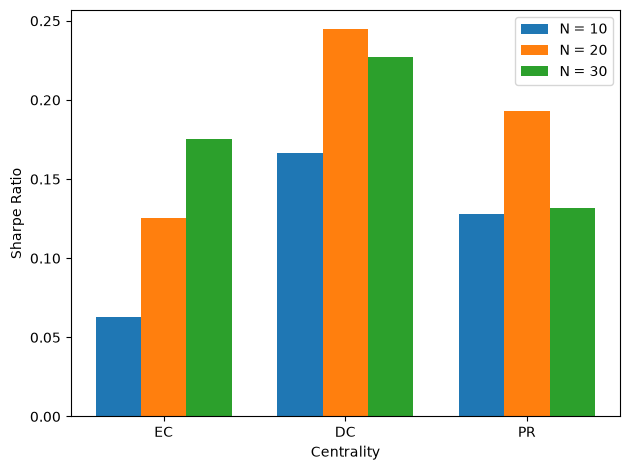

In [22]:
import matplotlib.pyplot as plt
import numpy as np

x = np.arange(len(centralities))
width = 0.25

plt.bar(x - width, [sharpe[c][10] for c in centralities], width, label="N = 10")
plt.bar(x,         [sharpe[c][20] for c in centralities], width, label="N = 20")
plt.bar(x + width, [sharpe[c][30] for c in centralities], width, label="N = 30")

plt.xlabel("Centrality")
plt.ylabel("Sharpe Ratio")
plt.xticks(x, centralities)
plt.legend()
plt.tight_layout()
plt.show()



  0.0% completed (0/1296)
  1.9% completed (25/1296)
  3.9% completed (50/1296)
  5.8% completed (75/1296)
  7.7% completed (100/1296)
  9.6% completed (125/1296)
 11.6% completed (150/1296)
 13.5% completed (175/1296)
 15.4% completed (200/1296)
 17.4% completed (225/1296)
 19.3% completed (250/1296)
 21.2% completed (275/1296)
 23.1% completed (300/1296)
 25.1% completed (325/1296)
 27.0% completed (350/1296)
 28.9% completed (375/1296)
 30.9% completed (400/1296)
 32.8% completed (425/1296)
 34.7% completed (450/1296)
 36.7% completed (475/1296)
 38.6% completed (500/1296)
 40.5% completed (525/1296)
 42.4% completed (550/1296)
 44.4% completed (575/1296)
 46.3% completed (600/1296)
 48.2% completed (625/1296)
 50.2% completed (650/1296)
 52.1% completed (675/1296)
 54.0% completed (700/1296)
 55.9% completed (725/1296)
 57.9% completed (750/1296)
 59.8% completed (775/1296)
 61.7% completed (800/1296)
 63.7% completed (825/1296)
 65.6% completed (850/1296)
 67.5% completed (875/129

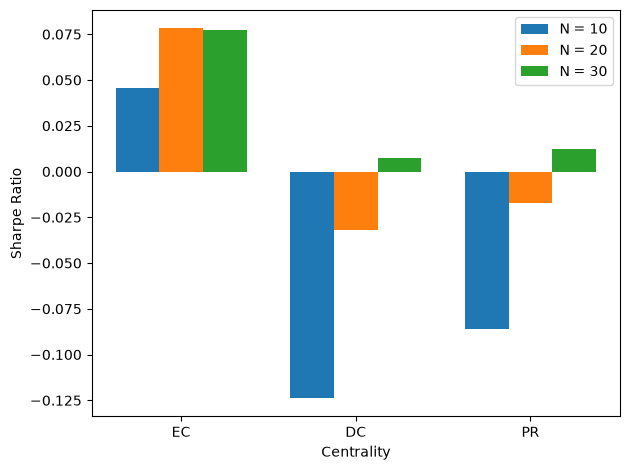

In [8]:
centralities= ["EC","DC","PR"]
portfolio_sizes= [10,20,30]

resultshigh= { c:{N: [] for N in portfolio_sizes} for c in centralities}
total= len(R)-264
for t in range(0,len(R)-260-4):
    window= R.iloc[t:t+260]
    test= R.iloc[t+260:t+265]
    
    if t%25==0 or t== total-1:
        print(f"{100*t/total:5.1f}% completed ({t}/{total})")
           
    PMFG = PMFG_graph(window)
    for c in centralities:
        if c=="EC":
                    centrality = nx.eigenvector_centrality(PMFG, weight=None, max_iter=1000, tol=1e-06) 
        elif c=="DC":
                    centrality = nx.degree_centrality(PMFG) 
        elif c=="PR":
                    centrality = nx.pagerank(PMFG, weight=None) 
    
        ranked_assets= sorted(centrality,reverse=True, key=centrality.get)
        for N in portfolio_sizes:
            selected= ranked_assets[:N]
            train= window[selected]
            weights= mean_var_strategy(train)
            daily_portfolio_returns = test[selected]@weights
            Rnet= np.sum(daily_portfolio_returns)
            resultshigh[c][N].append(Rnet)

np.save("resultshigh.npy",resultshigh)

import numpy as np
sharpe = {}

for c in resultshigh:
    sharpe[c]= {}
    for N in resultshigh[c]:
        r= np.array(resultshigh[c][N])
        sharpe[c][N]= r.mean()/ r.std(ddof=1)
print(sharpe)

import matplotlib.pyplot as plt

x = np.arange(len(centralities))
width = 0.25

plt.bar(x - width, [sharpe[c][10] for c in centralities], width, label="N = 10")
plt.bar(x,         [sharpe[c][20] for c in centralities], width, label="N = 20")
plt.bar(x + width, [sharpe[c][30] for c in centralities], width, label="N = 30")

plt.xlabel("Centrality")
plt.ylabel("Sharpe Ratio")
plt.xticks(x, centralities)
plt.legend()
plt.tight_layout()
plt.show()


In [8]:
import numpy as np
import pandas as pd
import networkx as nx

Rd= R/100
centralities    = ["EC", "DC", "PR"]
portfolio_sizes = [10, 20, 30]
W, H = 260, 5                       # window length, holding period

assets   = Rd.columns
starts   = range(0, len(Rd) - W - H + 1, H)   # non-overlapping rebalances
n_reb    = len(starts)

to_turnover = {c: {N: [] for N in portfolio_sizes} for c in centralities}
to_returns  = {c: {N: [] for N in portfolio_sizes} for c in centralities}
prev_w      = {c: {N: None for N in portfolio_sizes} for c in centralities}

for i, t in enumerate(starts):
    if i % 25 == 0 or i == n_reb - 1:
        print(f"{100*i/n_reb:5.1f}% completed ({i}/{n_reb})")

    window = Rd.iloc[t:t+W]
    test   = Rd.iloc[t+W:t+W+H]

    PMFG = PMFG_graph(window)

    for c in centralities:
        if c == "EC":
            centrality = nx.eigenvector_centrality(PMFG, weight=None, max_iter=1000, tol=1e-06)
        elif c == "DC":
            centrality = nx.degree_centrality(PMFG)
        else:
            centrality = nx.pagerank(PMFG, weight=None)

        ranked = sorted(centrality, key=centrality.get)

        for N in portfolio_sizes:
            selected = ranked[:N]
            weights  = mean_var_strategy(window[selected])

            # target weights over the full asset universe (omega_{j,t+1})
            w_new = pd.Series(0.0, index=assets)
            w_new[selected] = np.asarray(weights).ravel()

            # turnover against the drifted previous weights (omega_{j,t+})
            if prev_w[c][N] is not None:
                to_turnover[c][N].append(np.abs(w_new - prev_w[c][N]).sum())

            # portfolio return over the holding period
            to_returns[c][N].append((test[selected] @ weights).sum())

            # drift weights through the holding period (simple returns assumed)
            asset_growth = (1 + test).prod()
            drifted = w_new * asset_growth
            prev_w[c][N] = drifted / drifted.sum()

# Summary: TR (Eq. 19) and BETC (Eq. 20)
rows = []
for c in centralities:
    for N in portfolio_sizes:
        rows.append({
            "Centrality": c,
            "N": N,
            "TR":   np.mean(to_turnover[c][N]),
            "BETC": np.mean(to_returns[c][N]),   # = H/(T-M) * sum of daily returns
        })

summary = pd.DataFrame(rows).set_index(["Centrality", "N"])
print(summary.round(4))

  0.0% completed (0/260)
  9.6% completed (25/260)
 19.2% completed (50/260)
 28.8% completed (75/260)
 38.5% completed (100/260)
 48.1% completed (125/260)
 57.7% completed (150/260)
 67.3% completed (175/260)
 76.9% completed (200/260)
 86.5% completed (225/260)
 96.2% completed (250/260)
 99.6% completed (259/260)
                   TR    BETC
Centrality N                 
EC         10  0.8794  0.0076
           20  0.8091  0.0021
           30  0.6516 -0.0019
DC         10  0.6515  0.0031
           20  0.4750  0.0017
           30  0.4298  0.0012
PR         10  0.9573  0.0055
           20  0.6956  0.0007
           30  0.7069 -0.0028


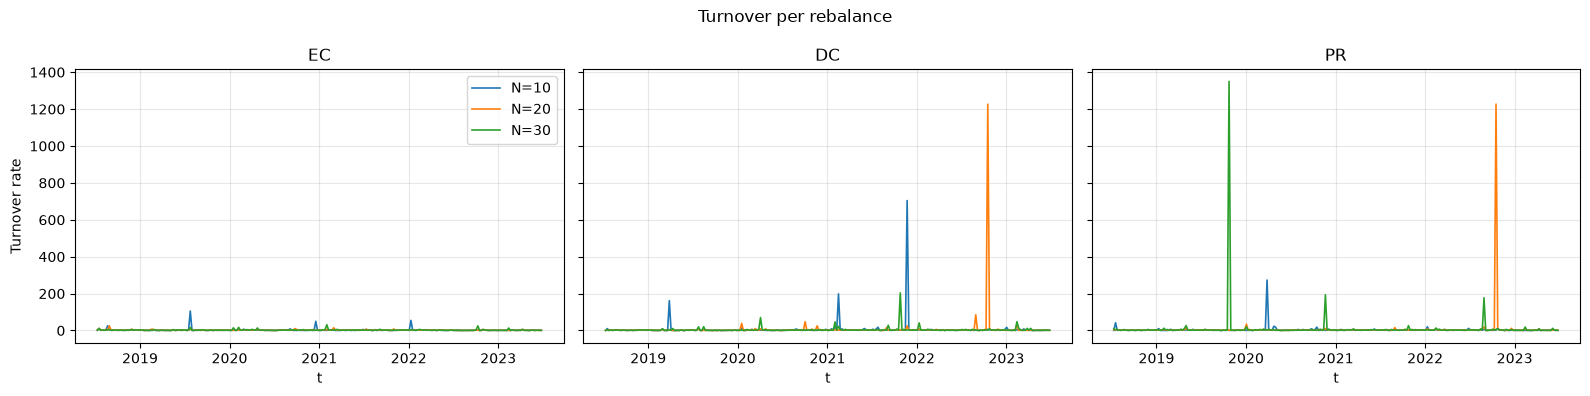

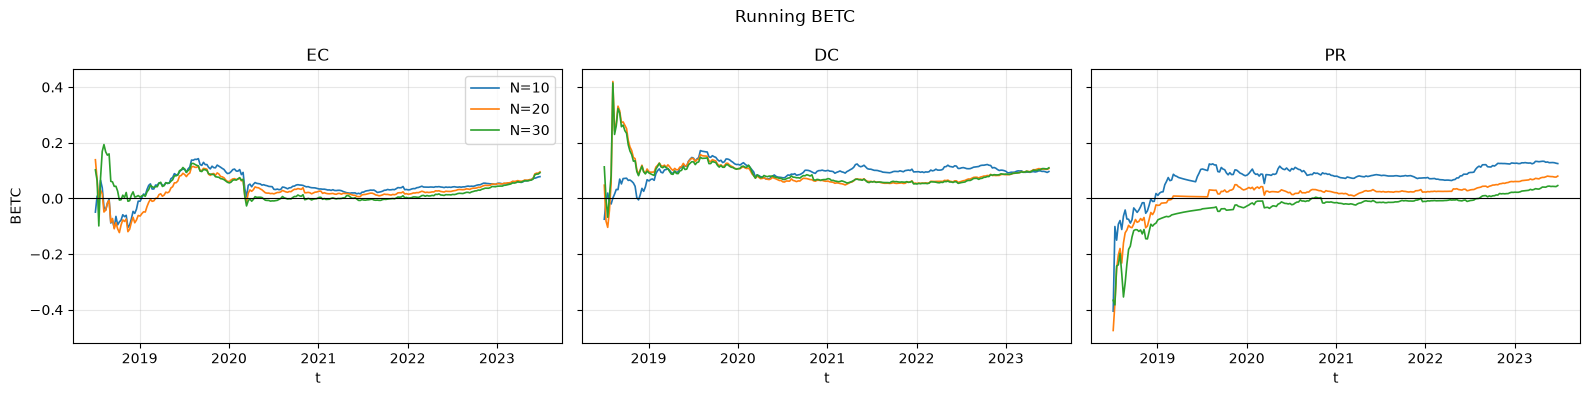

In [7]:
import matplotlib.pyplot as plt

# x-axis: date of each rebalance (first day of the test period)
x_all = [R.index[t + W] for t in starts]
x_to  = x_all[1:]                      # turnover has one fewer value (no previous portfolio at the first rebalance)

fig1, axes1 = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, c in zip(axes1, centralities):
    for N in portfolio_sizes:
        ax.plot(x_to, to_turnover[c][N], label=f"N={N}", lw=1.2)
    ax.set_title(f"{c}")
    ax.set_xlabel("t")
    ax.grid(alpha=0.3)
axes1[0].set_ylabel("Turnover rate")
axes1[0].legend()
fig1.suptitle("Turnover per rebalance")
plt.tight_layout()
plt.show()

fig2, axes2 = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, c in zip(axes2, centralities):
    for N in portfolio_sizes:
        r = np.array(to_returns[c][N])
        betc_t = np.cumsum(r) / np.arange(1, len(r) + 1)   # running BETC up to t
        ax.plot(x_all, betc_t, label=f"N={N}", lw=1.2)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_title(f"{c}")
    ax.set_xlabel("t")
    ax.grid(alpha=0.3)
axes2[0].set_ylabel("BETC")
axes2[0].legend()
fig2.suptitle("Running BETC")
plt.tight_layout()
plt.show()